In [2]:
# Check for GPU
!nvidia-smi -L

GPU 0: Tesla P100-PCIE-16GB (UUID: GPU-af864277-7913-4f7d-ffe3-c685a1a0c0d7)


In [3]:
# Download Bitcoin historical data from GitHub 
!wget https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/BTC_USD_2013-10-01_2021-05-18-CoinDesk.csv

--2024-10-11 07:48:18--  https://raw.githubusercontent.com/mrdbourke/tensorflow-deep-learning/main/extras/BTC_USD_2013-10-01_2021-05-18-CoinDesk.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 178509 (174K) [text/plain]
Saving to: 'BTC_USD_2013-10-01_2021-05-18-CoinDesk.csv'

BTC_USD_2013-10-01_ 100%[===================>] 174.33K  --.-KB/s    in 0.02s   

2024-10-11 07:48:18 (7.99 MB/s) - 'BTC_USD_2013-10-01_2021-05-18-CoinDesk.csv' saved [178509/178509]



### **Importing time series data with pandas**


In [4]:
# Import with pandas 
import pandas as pd
# Parse dates and set date column to index
df = pd.read_csv("BTC_USD_2013-10-01_2021-05-18-CoinDesk.csv", 
                 parse_dates=["Date"], 
                 index_col=["Date"]) # parse the date column (tell pandas column 1 is a datetime)
df.head()

,Currency,Closing Price (USD),24h Open (USD),24h High (USD),24h Low (USD)
Date,,,,,
2013-10-01,BTC,123.65499,124.30466,124.75166,122.56349
2013-10-02,BTC,125.45500,123.65499,125.75850,123.63383
2013-10-03,BTC,108.58483,125.45500,125.66566,83.32833
2013-10-04,BTC,118.67466,108.58483,118.67500,107.05816
2013-10-05,BTC,121.33866,118.67466,121.93633,118.00566


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2787 entries, 2013-10-01 to 2021-05-18
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Currency             2787 non-null   object 
 1   Closing Price (USD)  2787 non-null   float64
 2   24h Open (USD)       2787 non-null   float64
 3   24h High (USD)       2787 non-null   float64
 4   24h Low (USD)        2787 non-null   float64
dtypes: float64(4), object(1)
memory usage: 130.6+ KB


In [6]:
len(df)

2787

In [7]:
# Only want closing price for each day 
bitcoin_prices = pd.DataFrame(df["Closing Price (USD)"]).rename(columns={"Closing Price (USD)": "Price"})
bitcoin_prices.head()

,Price
Date,
2013-10-01,123.65499
2013-10-02,125.45500
2013-10-03,108.58483
2013-10-04,118.67466
2013-10-05,121.33866


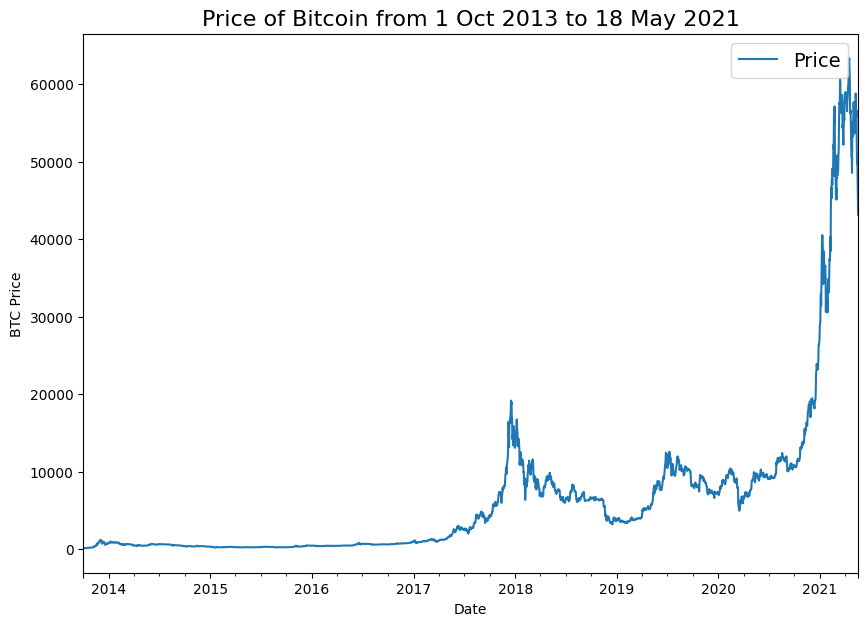

In [8]:
import matplotlib.pyplot as plt
bitcoin_prices.plot(figsize=(10, 7))
plt.ylabel("BTC Price")
plt.title("Price of Bitcoin from 1 Oct 2013 to 18 May 2021", fontsize=16)
plt.legend(fontsize=14);

### **Importing time series data with Python's CSV module**

In [9]:
import csv
from datetime import datetime

timesteps = []
btc_price = []

with open("/kaggle/working/BTC_USD_2013-10-01_2021-05-18-CoinDesk.csv","r") as f:
    csv_reader = csv.reader(f,delimiter = ",")
    next(csv_reader)
    for line in csv_reader:
        timesteps.append(datetime.strptime(line[1], "%Y-%m-%d"))
        btc_price.append(float(line[2]))
        
timesteps[:10],btc_price[:10]        

([datetime.datetime(2013, 10, 1, 0, 0),
  datetime.datetime(2013, 10, 2, 0, 0),
  datetime.datetime(2013, 10, 3, 0, 0),
  datetime.datetime(2013, 10, 4, 0, 0),
  datetime.datetime(2013, 10, 5, 0, 0),
  datetime.datetime(2013, 10, 6, 0, 0),
  datetime.datetime(2013, 10, 7, 0, 0),
  datetime.datetime(2013, 10, 8, 0, 0),
  datetime.datetime(2013, 10, 9, 0, 0),
  datetime.datetime(2013, 10, 10, 0, 0)],
 [123.65499,
  125.455,
  108.58483,
  118.67466,
  121.33866,
  120.65533,
  121.795,
  123.033,
  124.049,
  125.96116])

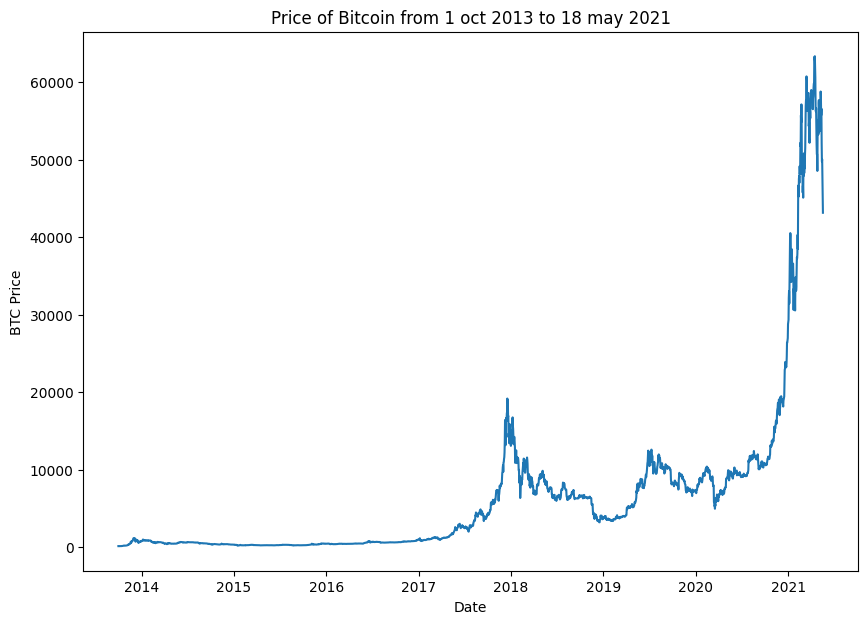

In [10]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(10,7))
plt.plot(timesteps,btc_price)
plt.title("Price of Bitcoin from 1 oct 2013 to 18 may 2021")
plt.xlabel("Date")
plt.ylabel("BTC Price");

### **Create train & test sets for time series (the wrong way)**

In [11]:
timesteps = bitcoin_prices.index.to_numpy()
prices = bitcoin_prices["Price"].to_numpy()

In [12]:
timesteps[:10],prices[:10]

(array(['2013-10-01T00:00:00.000000000', '2013-10-02T00:00:00.000000000',
        '2013-10-03T00:00:00.000000000', '2013-10-04T00:00:00.000000000',
        '2013-10-05T00:00:00.000000000', '2013-10-06T00:00:00.000000000',
        '2013-10-07T00:00:00.000000000', '2013-10-08T00:00:00.000000000',
        '2013-10-09T00:00:00.000000000', '2013-10-10T00:00:00.000000000'],
       dtype='datetime64[ns]'),
 array([123.65499, 125.455  , 108.58483, 118.67466, 121.33866, 120.65533,
        121.795  , 123.033  , 124.049  , 125.96116]))

In [13]:
#  wrong way to make split
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(timesteps,
                                                prices,
                                                test_size=0.2,
                                                random_state=42)

In [14]:
x_train.shape,x_test.shape

((2229,), (558,))

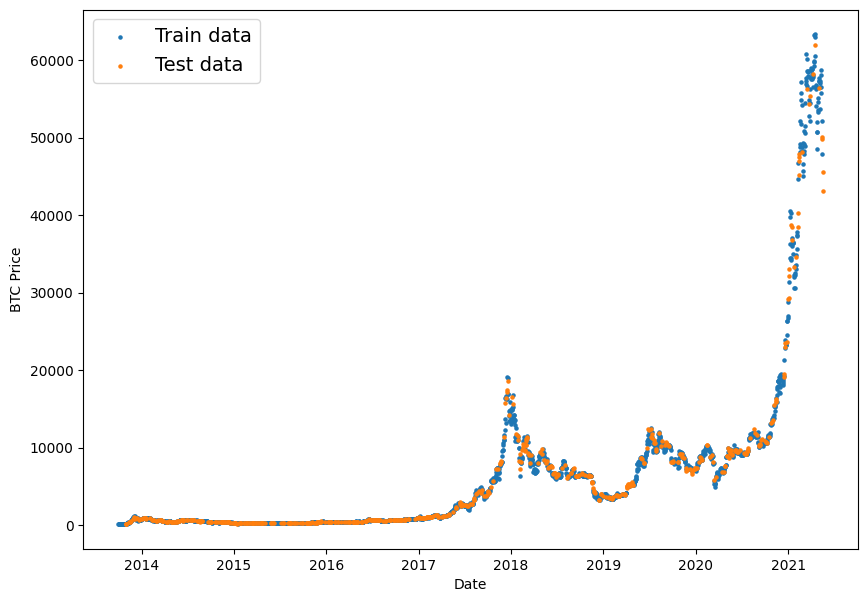

In [15]:
# plot wrong train and test splits
plt.figure(figsize=(10,7))
plt.scatter(x_train,y_train,s=5,label = "Train data")
plt.scatter(x_test,y_test,s=5,label = "Test data")
plt.xlabel("Date")
plt.ylabel("BTC Price")
plt.legend(fontsize=14);

### **Create train & test sets for time series (the right way)**

In [16]:
split_size = int(0.8 *len(prices))

x_train , y_train = timesteps[:split_size],prices[:split_size]

x_test , y_test = timesteps[split_size:],prices[split_size:]

In [17]:
len(x_train), len(x_test), len(y_train), len(y_test)

(2229, 558, 2229, 558)

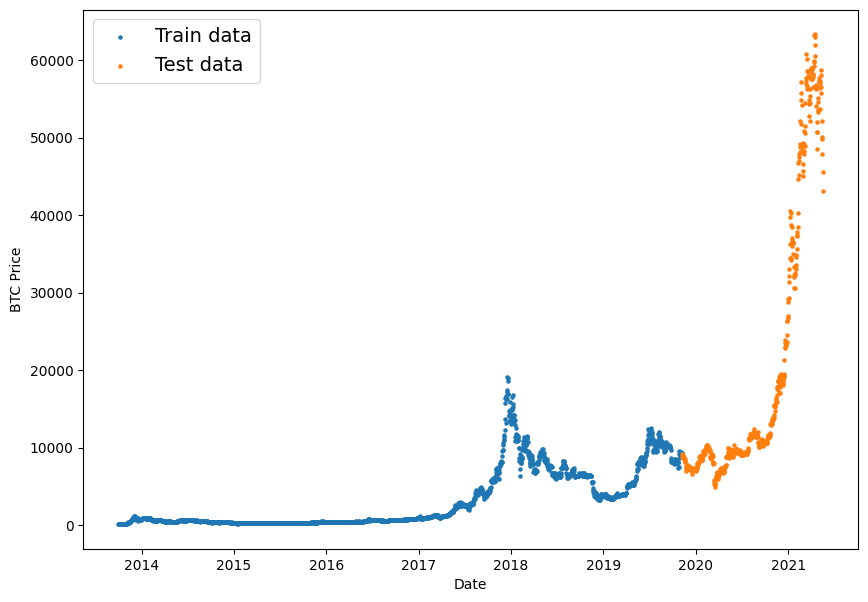

In [18]:
# plot wrong train and test splits
plt.figure(figsize=(10,7))
plt.scatter(x_train,y_train,s=5,label = "Train data")
plt.scatter(x_test,y_test,s=5,label = "Test data")
plt.xlabel("Date")
plt.ylabel("BTC Price")
plt.legend(fontsize=14);

### **Create a plotting function**

In [19]:
def plot_time_series(timesteps, values, format='.', start=0, end=None, label=None):
  # Plot the series
    plt.plot(timesteps[start:end], values[start:end], format, label=label)
    plt.xlabel("Time")
    plt.ylabel("BTC Price")
    if label:
        plt.legend(fontsize=14) # make label bigger
    plt.grid(True)

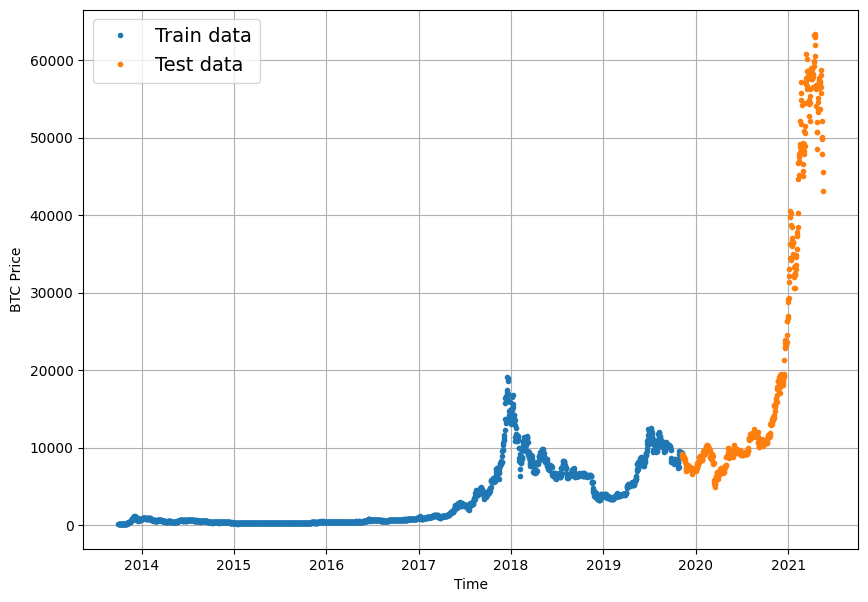

In [20]:
# Try out our plotting function
plt.figure(figsize=(10, 7))
plot_time_series(timesteps=x_train, values=y_train, label="Train data")
plot_time_series(timesteps=x_test, values=y_test, label="Test data")

## **Modelling Experiments**

### **Model 0: Naïve forecast (baseline)**

In [21]:
naive_forecast = y_test[:-1]
naive_forecast[:10],naive_forecast[-10:]

(array([9226.48582088, 8794.35864452, 8798.04205463, 9081.18687849,
        8711.53433917, 8760.89271814, 8749.52059102, 8656.97092235,
        8500.64355816, 8469.2608989 ]),
 array([57107.12067189, 58788.20967893, 58102.19142623, 55715.54665129,
        56573.5554719 , 52147.82118698, 49764.1320816 , 50032.69313676,
        47885.62525472, 45604.61575361]))

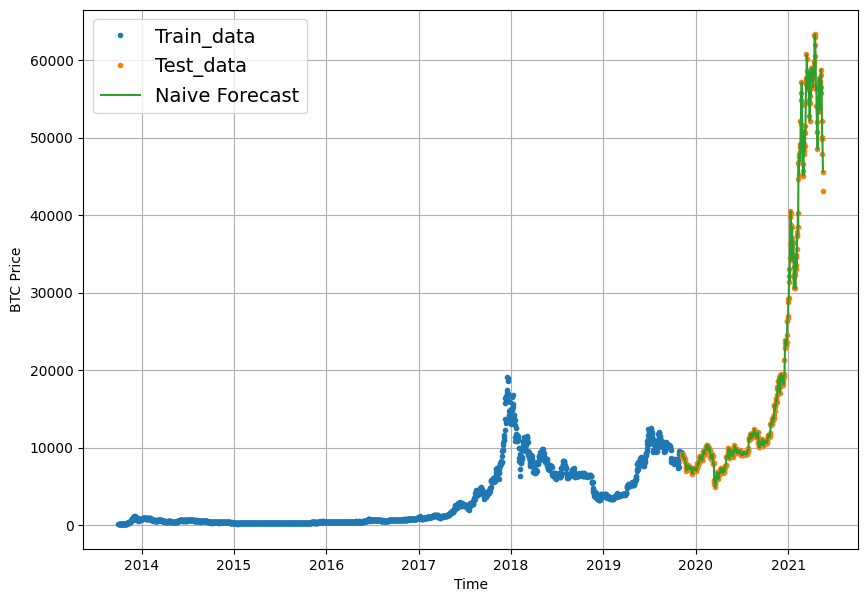

In [22]:
plt.figure(figsize=(10,7))
plot_time_series(timesteps=x_train,values=y_train,label="Train_data")
plot_time_series(timesteps=x_test,values=y_test,label="Test_data")
plot_time_series(timesteps=x_test[1:],values=naive_forecast,format='-',label="Naive Forecast")

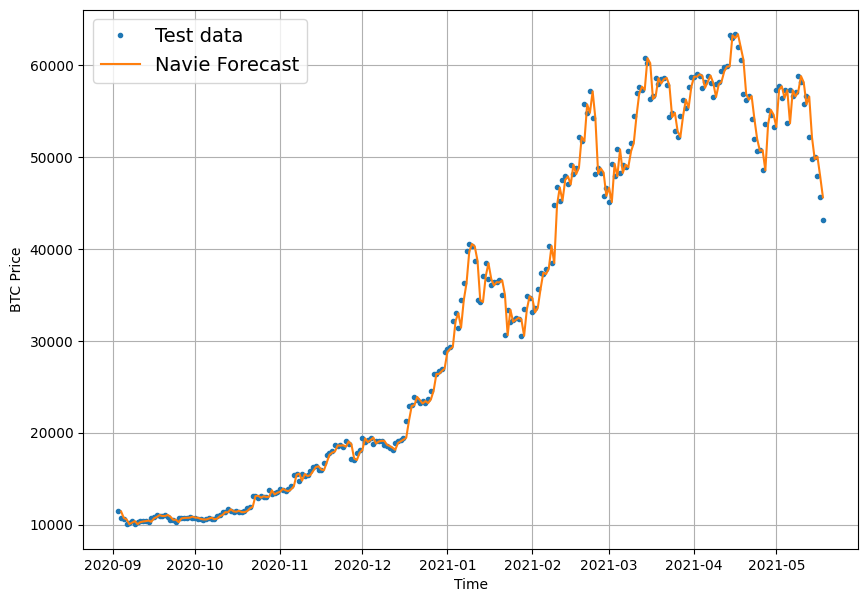

In [23]:
plt.figure(figsize=(10,7))
offset = 300
plot_time_series(timesteps=x_test,values=y_test,start=offset,label="Test data")
plot_time_series(timesteps=x_test[1:],values=naive_forecast,format="-", start=offset, label="Navie Forecast")

### **Build function to check performence**

In [24]:
import tensorflow as tf

In [25]:
import tensorflow as tf

def mean_absolute_scaled_error(y_true, y_pred):
    mae = tf.reduce_mean(tf.abs(y_true - y_pred))
    naive_pred = tf.concat([y_true[1:], [y_true[-1]]], axis=0)
    naive_mae = tf.reduce_mean(tf.abs(y_true - naive_pred))
    return mae / naive_mae

# Function to evaluate predictions
def evaluate_preds(y_true, y_pred):
    y_true = tf.cast(y_true, dtype=tf.float32)
    y_pred = tf.cast(y_pred, dtype=tf.float32)
    
    mae_metric = tf.keras.metrics.MeanAbsoluteError()
    mse_metric = tf.keras.metrics.MeanSquaredError()
    mape_metric = tf.keras.metrics.MeanAbsolutePercentageError()

    # Update the metric states with the true and predicted values
    mae_metric.update_state(y_true, y_pred)
    mse_metric.update_state(y_true, y_pred)
    mape_metric.update_state(y_true, y_pred)

    # Calculate various metrics
    mae = mae_metric.result()
    mse = mse_metric.result()
    rmse = tf.sqrt(mse)
    mape = mape_metric.result()
    mase = mean_absolute_scaled_error(y_true, y_pred)
    
    return {
        "mae": mae.numpy(),
        "mse": mse.numpy(),
        "rmse": rmse.numpy(),
        "mape": mape.numpy(),
        "mase": mase.numpy()
    }


In [26]:
naive_result = evaluate_preds(y_true=y_test[1:],
                             y_pred=naive_forecast)
naive_result

{'mae': 567.9802,
 'mse': 1147547.0,
 'rmse': 1071.2362,
 'mape': 2.516525,
 'mase': 1.0013678}

In [27]:
# find average price of bitcoin in test dataset

tf.reduce_mean(y_test).numpy()

20056.632963737222

### **Other kinds of time series forecasting models which can be used for baselines and actual forecasts**

In [28]:
HORIZON = 1 # predict 1 step at a time
WINDOW_SIZE = 7 # use a week worth of timesteps to predict the horizon

In [29]:
# Create function to label windowed data
def get_labelled_windows(x, horizon=1):
  """
  Creates labels for windowed dataset.

  E.g. if horizon=1 (default)
  Input: [1, 2, 3, 4, 5, 6] -> Output: ([1, 2, 3, 4, 5], [6])
  """
  return x[:, :-horizon], x[:, -horizon:]

In [30]:
tf.expand_dims(tf.range(8)+1,axis=0)[:,:-1]

<tf.Tensor: shape=(1, 7), dtype=int32, numpy=array([[1, 2, 3, 4, 5, 6, 7]], dtype=int32)>

In [31]:
tf.expand_dims(tf.range(8)+1,axis=0)[:,-1]

<tf.Tensor: shape=(1,), dtype=int32, numpy=array([8], dtype=int32)>

In [32]:
test_window ,test_label = get_labelled_windows(tf.expand_dims(tf.range(8)+1,axis=0),horizon=HORIZON)
print(f"Window : {tf.squeeze(test_window).numpy()} -> Label: {tf.squeeze(test_label).numpy()}")

Window : [1 2 3 4 5 6 7] -> Label: 8


## **Analysistion**

In [33]:
len(prices)

2787

In [34]:
prices

array([  123.65499   ,   125.455     ,   108.58483   , ...,
       47885.62525472, 45604.61575361, 43144.47129086])

In [35]:
window_step = np.expand_dims(np.arange( WINDOW_SIZE + HORIZON),axis=0)
window_step

array([[0, 1, 2, 3, 4, 5, 6, 7]])

In [36]:
x = prices
window_size =7
horizon =1

In [37]:
window_index = np.expand_dims(np.arange(len(x)-(window_size + horizon-1)),axis=0)
window_index.T

array([[   0],
       [   1],
       [   2],
       ...,
       [2777],
       [2778],
       [2779]])

In [38]:
window_index

array([[   0,    1,    2, ..., 2777, 2778, 2779]])

In [39]:
y = window_step + window_index.T
y

array([[   0,    1,    2, ...,    5,    6,    7],
       [   1,    2,    3, ...,    6,    7,    8],
       [   2,    3,    4, ...,    7,    8,    9],
       ...,
       [2777, 2778, 2779, ..., 2782, 2783, 2784],
       [2778, 2779, 2780, ..., 2783, 2784, 2785],
       [2779, 2780, 2781, ..., 2784, 2785, 2786]])

In [40]:
y[:2]

array([[0, 1, 2, 3, 4, 5, 6, 7],
       [1, 2, 3, 4, 5, 6, 7, 8]])

## ***Function***

In [41]:
# Create function to view NumPy arrays as windows 
def make_windows(x, window_size=7, horizon=1):
  """
  Turns a 1D array into a 2D array of sequential windows of window_size.
  """
  # 1. Create a window of specific window_size (add the horizon on the end for later labelling)
  window_step = np.expand_dims(np.arange(window_size+horizon), axis=0)
  # print(f"Window step:\n {window_step}")

  # 2. Create a 2D array of multiple window steps (minus 1 to account for 0 indexing)
  window_indexes = window_step + np.expand_dims(np.arange(len(x)-(window_size+horizon-1)), axis=0).T # create 2D array of windows of size window_size
  # print(f"Window indexes:\n {window_indexes[:3], window_indexes[-3:], window_indexes.shape}")

  # 3. Index on the target array (time series) with 2D array of multiple window steps
  windowed_array = x[window_indexes]

  # 4. Get the labelled windows
  windows, labels = get_labelled_windows(windowed_array, horizon=horizon)

  return windows, labels

In [42]:
full_windows, full_labels = make_windows(prices, window_size= 7, horizon=1)
len(full_windows), len(full_labels)

(2780, 2780)

In [43]:
full_windows

array([[  123.65499   ,   125.455     ,   108.58483   , ...,
          121.33866   ,   120.65533   ,   121.795     ],
       [  125.455     ,   108.58483   ,   118.67466   , ...,
          120.65533   ,   121.795     ,   123.033     ],
       [  108.58483   ,   118.67466   ,   121.33866   , ...,
          121.795     ,   123.033     ,   124.049     ],
       ...,
       [58788.20967893, 58102.19142623, 55715.54665129, ...,
        52147.82118698, 49764.1320816 , 50032.69313676],
       [58102.19142623, 55715.54665129, 56573.5554719 , ...,
        49764.1320816 , 50032.69313676, 47885.62525472],
       [55715.54665129, 56573.5554719 , 52147.82118698, ...,
        50032.69313676, 47885.62525472, 45604.61575361]])

In [44]:
full_labels

array([[  123.033     ],
       [  124.049     ],
       [  125.96116   ],
       ...,
       [47885.62525472],
       [45604.61575361],
       [43144.47129086]])

In [45]:
# View the first 3 windows/labels
for i in range(3):
  print(f"Window: {full_windows[i]} -> Label: {full_labels[i]}")

Window: [123.65499 125.455   108.58483 118.67466 121.33866 120.65533 121.795  ] -> Label: [123.033]
Window: [125.455   108.58483 118.67466 121.33866 120.65533 121.795   123.033  ] -> Label: [124.049]
Window: [108.58483 118.67466 121.33866 120.65533 121.795   123.033   124.049  ] -> Label: [125.96116]


### ***Turning windows into training and test sets***

In [46]:
# Make the train/test splits
def make_train_test_splits(windows, labels, test_split=0.2):
  """
  Splits matching pairs of windows and labels into train and test splits.
  """
  split_size = int(len(windows) * (1-test_split)) # this will default to 80% train/20% test
  train_windows = windows[:split_size]
  train_labels = labels[:split_size]
  test_windows = windows[split_size:]
  test_labels = labels[split_size:]
  return train_windows, test_windows, train_labels, test_labels

In [47]:
train_windows, test_windows, train_labels, test_labels = make_train_test_splits(full_windows, full_labels)
len(train_windows), len(test_windows), len(train_labels), len(test_labels)

(2224, 556, 2224, 556)

In [48]:
train_windows[:5], train_labels[:5]

(array([[123.65499, 125.455  , 108.58483, 118.67466, 121.33866, 120.65533,
         121.795  ],
        [125.455  , 108.58483, 118.67466, 121.33866, 120.65533, 121.795  ,
         123.033  ],
        [108.58483, 118.67466, 121.33866, 120.65533, 121.795  , 123.033  ,
         124.049  ],
        [118.67466, 121.33866, 120.65533, 121.795  , 123.033  , 124.049  ,
         125.96116],
        [121.33866, 120.65533, 121.795  , 123.033  , 124.049  , 125.96116,
         125.27966]]),
 array([[123.033  ],
        [124.049  ],
        [125.96116],
        [125.27966],
        [125.9275 ]]))

In [49]:
train_labels[:-HORIZON]

array([[ 123.033     ],
       [ 124.049     ],
       [ 125.96116   ],
       ...,
       [9326.59962378],
       [9335.75240233],
       [9226.48582088]])

In [50]:
y_train[WINDOW_SIZE:]

array([ 123.033     ,  124.049     ,  125.96116   , ..., 9369.62808116,
       9326.59962378, 9335.75240233])

In [51]:
np.array_equal(np.squeeze(train_labels[:-HORIZON-1]), y_train[WINDOW_SIZE:])

True

### ***Make a modelling checkpoint***

In [52]:
import os
def create_model_checkpoint(model_name,save_path = "model_experiments"):
    return tf.keras.callbacks.ModelCheckpoint(filepath = os.path.join(save_path,model_name),
                                             verbose=0,
                                             save_best_only = True)

 ### ***Model 1: Dense model (window = 7, horizon = 1)***

In [53]:
import tensorflow as tf
from tensorflow.keras import layers

tf.random.set_seed(42)

model_1 = tf.keras.Sequential([
    layers.Dense(128,activation = "relu"),
    layers.Dense(HORIZON,activation="linear"),
],name = "model_1_dense")

model_1.compile(loss="mae",
               optimizer=tf.keras.optimizers.Adam(),
               metrics = ["mae"])

model_1_history = model_1.fit(train_windows,
                             train_labels,
                              epochs=100,
                             verbose=1,
                             batch_size=128,
                             validation_data=(test_windows,test_labels),
                             callbacks=[create_model_checkpoint(model_name="model_1.keras")])
                             

Epoch 1/100


I0000 00:00:1728632917.402956     106 service.cc:145] XLA service 0x7979e0016550 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1728632917.403018     106 service.cc:153]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0


 1/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - loss: 1997.7751 - mae: 1997.7751

I0000 00:00:1728632917.938535     106 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1059.4437 - mae: 1059.4437 - val_loss: 1105.7867 - val_mae: 1105.7867
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 205.2608 - mae: 205.2608 - val_loss: 948.7520 - val_mae: 948.7520
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 167.2793 - mae: 167.2793 - val_loss: 985.6386 - val_mae: 985.6386
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 156.3840 - mae: 156.3840 - val_loss: 865.2993 - val_mae: 865.2993
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 149.4161 - mae: 149.4161 - val_loss: 884.6497 - val_mae: 884.6497
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 145.7418 - mae: 145.7418 - val_loss: 818.6315 - val_mae: 818.6315
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 141.5433 - mae: 141.5433 - val_loss: 815.8199 - val_mae: 815.8199
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 138.5844 - mae: 138.5844 - val_loss: 779.5994 - val_mae: 779.5994
Epoch 9

In [54]:
model_1.evaluate(test_windows,test_labels)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 282.0142 - mae: 282.0142 


[563.7197875976562, 563.7197875976562]

In [55]:
# Load in saved best performing model_1 and evaluate on test data
model_1 = tf.keras.models.load_model("model_experiments/model_1.keras")
model_1.evaluate(test_windows, test_labels)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 280.4208 - mae: 280.4208 


[562.515380859375, 562.515380859375]

### **Making forecasts with a model (on the test dataset)**

In [56]:
def make_preds(model,input_data):
    forcast = model.predict(input_data)
    return tf.squeeze(forcast)

In [57]:
model_1_preds = make_preds(model_1,test_windows)
model_1_preds[:10]

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([8847.852, 8807.178, 9065.979, 8775.604, 8759.65 , 8760.597,
       8668.491, 8557.673, 8463.686, 8548.092], dtype=float32)>

In [58]:
len(model_1_preds)

556

In [59]:
# Evaluate preds
model_1_results = evaluate_preds(y_true=tf.squeeze(test_labels), # reduce to right shape
                                 y_pred=model_1_preds)
model_1_results

{'mae': 562.51544,
 'mse': 1149832.5,
 'rmse': 1072.3024,
 'mape': 2.5091753,
 'mase': 0.9899643}

In [60]:
naive_result

{'mae': 567.9802,
 'mse': 1147547.0,
 'rmse': 1071.2362,
 'mape': 2.516525,
 'mase': 1.0013678}

In [61]:
model_1_preds[:10],test_labels[:10]

(<tf.Tensor: shape=(10,), dtype=float32, numpy=
 array([8847.852, 8807.178, 9065.979, 8775.604, 8759.65 , 8760.597,
        8668.491, 8557.673, 8463.686, 8548.092], dtype=float32)>,
 array([[8798.04205463],
        [9081.18687849],
        [8711.53433917],
        [8760.89271814],
        [8749.52059102],
        [8656.97092235],
        [8500.64355816],
        [8469.2608989 ],
        [8537.33965197],
        [8205.80636599]]))

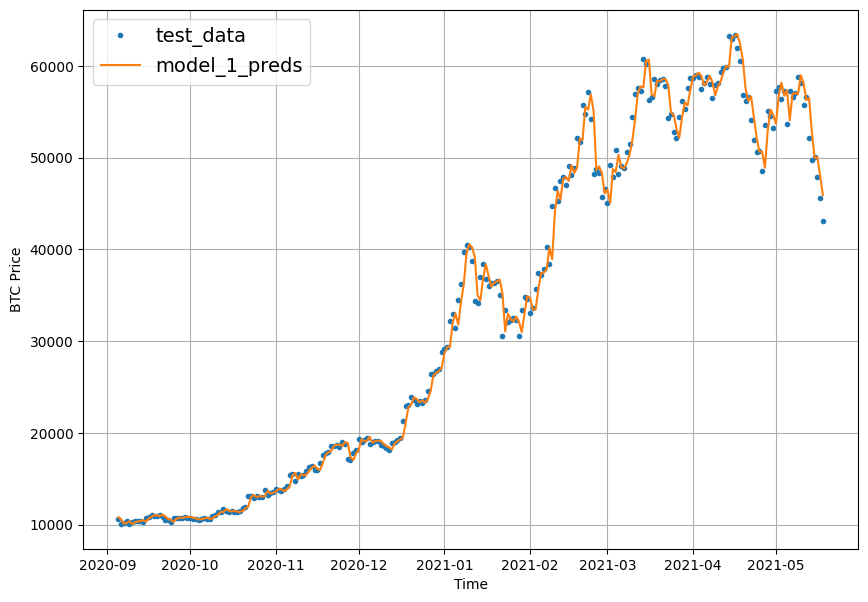

In [62]:
offset =300
plt.figure(figsize=(10,7))
plot_time_series(timesteps=x_test[-len(test_windows):],values = test_labels,start=offset,label="test_data")
plot_time_series(timesteps=x_test[-len(test_windows):],values = model_1_preds,start=offset,format="-" ,label="model_1_preds")

### ***Model 2: Dense (window = 30, horizon = 1)***

In [63]:
HORIZON = 1
WINDOW_SIZE = 30

In [64]:
full_windows,full_labels = make_windows(prices ,window_size=WINDOW_SIZE,horizon=HORIZON)


In [65]:
len(full_windows), len(full_labels)

(2757, 2757)

In [66]:
# Make train and testing windows
train_windows, test_windows, train_labels, test_labels = make_train_test_splits(windows=full_windows, labels=full_labels)
len(train_windows), len(test_windows), len(train_labels), len(test_labels)

(2205, 552, 2205, 552)

In [67]:
tf.random.set_seed(42)

model_2 =tf.keras.Sequential([
    layers.Dense(128,activation="relu"),
    layers.Dense(HORIZON)
],name="model_2_dense")

model_2.compile(loss='mae',
               optimizer=tf.keras.optimizers.Adam(),
               )
model_2_history = model_2.fit(train_windows,
                             train_labels,
                             epochs=100,
                             verbose=0,
                              batch_size=128,
                              validation_data = (test_windows,test_labels),
                              callbacks = [create_model_checkpoint(model_name="model_2.keras")]
                            
                    )

In [68]:
# Evaluate model 2 preds
model_2.evaluate(test_windows, test_labels)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 379.4277 


708.7476196289062

In [69]:
# Load in best performing model
model_2 = tf.keras.models.load_model("model_experiments/model_2.keras")
model_2.evaluate(test_windows, test_labels)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 316.9211 


619.8304443359375

In [70]:
# Get forecast predictions
model_2_preds = make_preds(model_2,
                           input_data=test_windows)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [71]:
model_2_results = evaluate_preds(y_true=tf.squeeze(test_labels), # remove 1 dimension of test labels
                                 y_pred=model_2_preds)
model_2_results

{'mae': 619.83044,
 'mse': 1302923.4,
 'rmse': 1141.4567,
 'mape': 2.79904,
 'mase': 1.0854361}

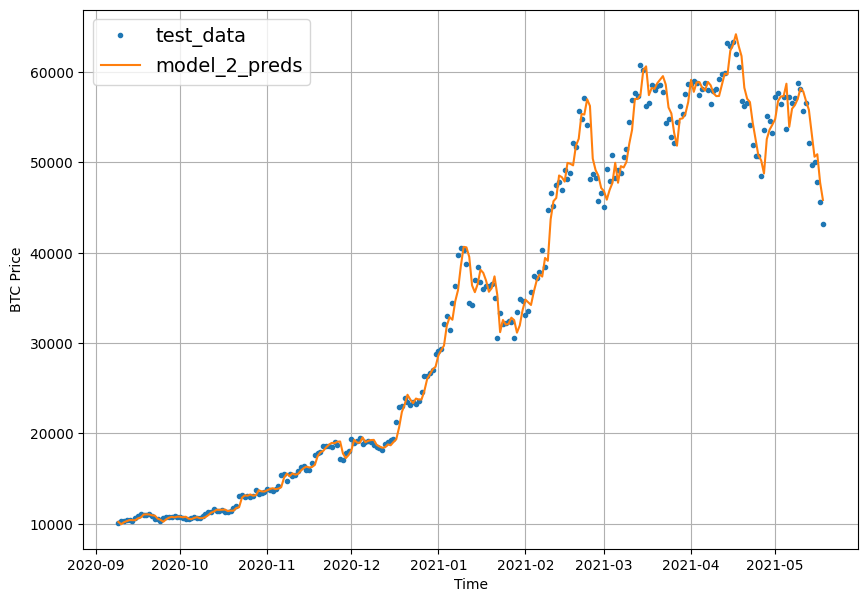

In [72]:
offset = 300
plt.figure(figsize=(10, 7))
# Account for the test_window offset
plot_time_series(timesteps=x_test[-len(test_windows):], values=test_labels, start=offset, label="test_data")
plot_time_series(timesteps=x_test[-len(test_windows):], values=model_2_preds, start=offset, format="-", label="model_2_preds") 
     

### ***Model 3: Dense(window = 30, horizon =7)***

In [73]:
HORIZON = 7
WINDOW_SIZE = 30

full_windows, full_labels = make_windows(prices, window_size=WINDOW_SIZE, horizon=HORIZON)
len(full_windows), len(full_labels)

(2751, 2751)

In [74]:
train_windows, test_windows, train_labels, test_labels = make_train_test_splits(windows=full_windows, labels=full_labels, test_split=0.2)
len(train_windows), len(test_windows), len(train_labels), len(test_labels)

(2200, 551, 2200, 551)

In [75]:
tf.random.set_seed(42)

# Create model (same as model_1 except with different data input size)
model_3 = tf.keras.Sequential([
  layers.Dense(128, activation="relu"),
  layers.Dense(HORIZON)
], name="model_3_dense")

model_3.compile(loss="mae",
                optimizer=tf.keras.optimizers.Adam())

model_3.fit(train_windows,
            train_labels,
            batch_size=128,
            epochs=100,
            verbose=0,
            validation_data=(test_windows, test_labels),
           
            callbacks = [create_model_checkpoint(model_name="model_3.keras")]

           )

In [76]:
# How did our model with a larger window size and horizon go?
model_3.evaluate(test_windows, test_labels)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 634.5921 


1274.29052734375

In [77]:
model_3 = tf.keras.models.load_model("model_experiments/model_3.keras")
model_3.evaluate(test_windows, test_labels)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 636.4808 


1265.513427734375

In [78]:
# The predictions are going to be 7 steps at a time (this is the HORIZON size)
model_3_preds = make_preds(model_3,
                           input_data=test_windows)
model_3_preds[:5]

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


<tf.Tensor: shape=(5, 7), dtype=float32, numpy=
array([[9488.611, 9621.647, 9539.855, 9566.436, 9297.651, 9489.943,
        9464.279],
       [9139.837, 9268.25 , 9157.379, 9331.795, 9113.193, 9120.461,
        8989.87 ],
       [8985.022, 8957.908, 8900.689, 8991.213, 9076.103, 8960.734,
        8573.558],
       [8996.61 , 9006.936, 9084.304, 9014.222, 9168.736, 9143.295,
        8715.817],
       [8918.731, 8944.061, 8990.347, 9155.142, 9066.282, 8931.575,
        8804.716]], dtype=float32)>

In [79]:
model_3_results = evaluate_preds(y_true=tf.squeeze(test_labels),
                                 y_pred=model_3_preds)
model_3_results
     

{'mae': 1265.5134,
 'mse': 5568592.5,
 'rmse': 2359.7866,
 'mape': 5.6760883,
 'mase': 2.2560046}

### ***Make our evaluation function work for larger horizons***

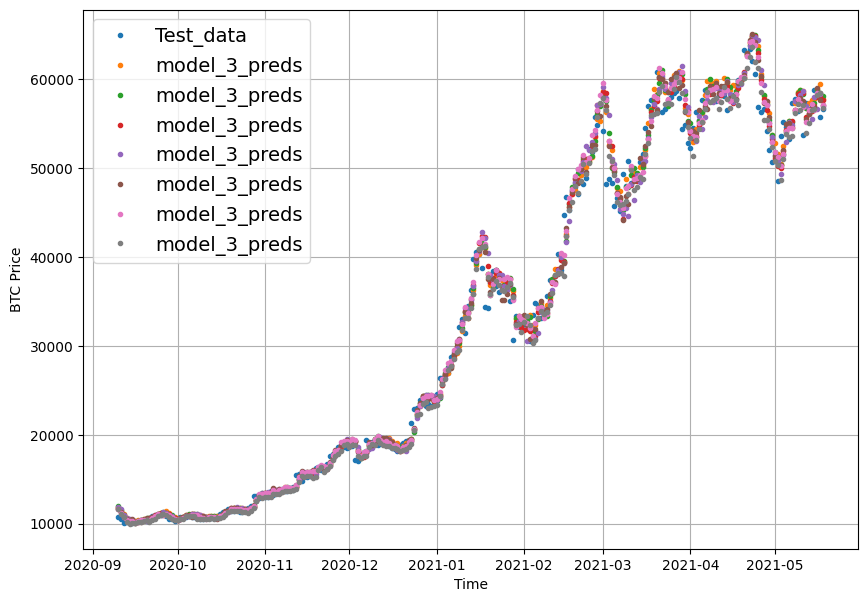

In [80]:
offset = 300
plt.figure(figsize=(10, 7))
plot_time_series(timesteps=x_test[-len(test_windows):], values=test_labels[:, 0], start=offset, label="Test_data")
plot_time_series(timesteps=x_test[-len(test_windows):], values=model_3_preds, start=offset, label="model_3_preds")
     

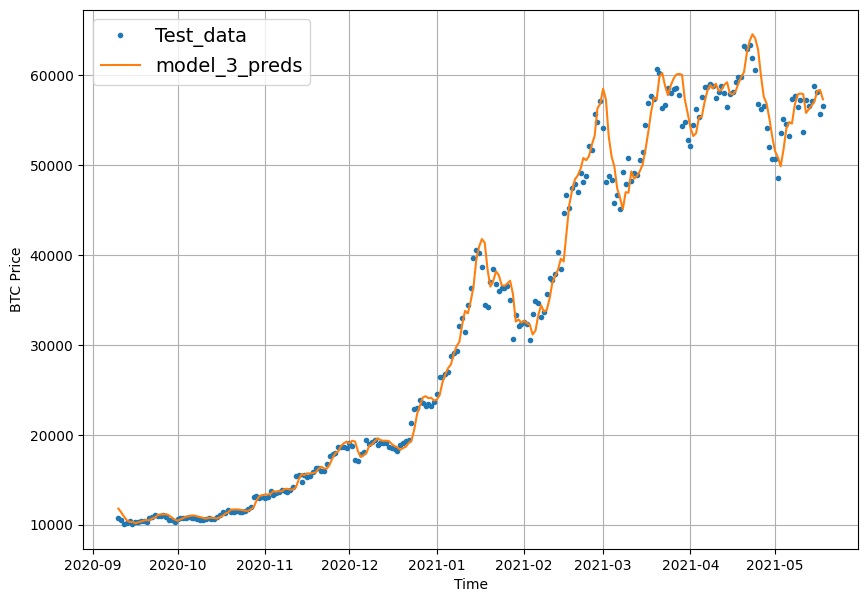

In [81]:

offset = 300
plt.figure(figsize=(10, 7))
# Plot model_3_preds by aggregating them (note: this condenses information so the preds will look fruther ahead than the test data)
plot_time_series(timesteps=x_test[-len(test_windows):], 
                 values=test_labels[:, 0], 
                 start=offset, 
                 label="Test_data")
plot_time_series(timesteps=x_test[-len(test_windows):], 
                 values=tf.reduce_mean(model_3_preds, axis=1), 
                 format="-",
                 start=offset, 
                 label="model_3_preds")

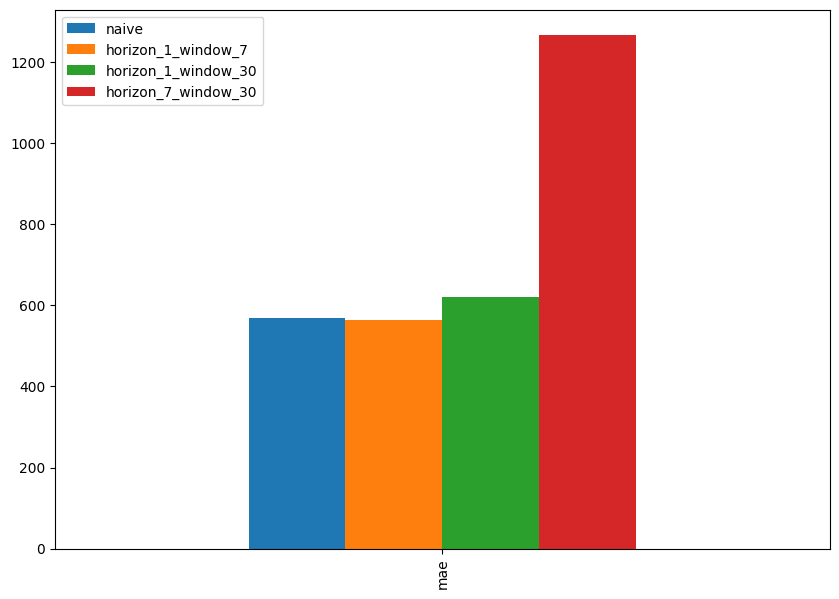

In [82]:
pd.DataFrame({"naive": naive_result["mae"], 
              "horizon_1_window_7": model_1_results["mae"], 
              "horizon_1_window_30": model_2_results["mae"], 
              "horizon_7_window_30": model_3_results["mae"]}, index=["mae"]).plot(figsize=(10, 7), kind="bar");
     

### ***Model 4: Conv1D***

In [83]:
HORIZON = 1
WINDOW_SIZE = 7

In [84]:
full_windows, full_labels = make_windows(prices, window_size=WINDOW_SIZE, horizon=HORIZON)
len(full_windows), len(full_labels)

(2780, 2780)

In [85]:
# Create train/test splits
train_windows, test_windows, train_labels, test_labels = make_train_test_splits(full_windows, full_labels)
len(train_windows), len(test_windows), len(train_labels), len(test_labels)

(2224, 556, 2224, 556)

In [86]:
train_windows[0].shape

(7,)

In [87]:
x = tf.constant(train_windows[0])
expand_dims_layer = layers.Lambda(lambda x : tf.expand_dims(x,axis=1))

In [88]:

print(f"Original shape: {x.shape}") # (WINDOW_SIZE)
print(f"Expanded shape: {expand_dims_layer(x).shape}") # (WINDOW_SIZE, input_dim) 
print(f"Original values with expanded shape:\n {expand_dims_layer(x)}")

Original shape: (7,)
Expanded shape: (7, 1)
Original values with expanded shape:
 [[123.65499]
 [125.455  ]
 [108.58483]
 [118.67466]
 [121.33866]
 [120.65533]
 [121.795  ]]


In [89]:
tf.random.set_seed(42)

# because input size is 2d some x is 2d

model_4 = tf.keras.Sequential([
    layers.Lambda(lambda x: tf.expand_dims(x,axis=1)),
    layers.Conv1D(filters=128,kernel_size=5,padding="causal",activation="relu"),
    layers.Dense(HORIZON)
],name="model_4_conv1D")

model_4.compile(loss="mae",
               optimizer=tf.keras.optimizers.Adam())

model_4_history = model_4.fit(train_windows,
                             train_labels,
                             batch_size=128,
                             epochs=100,
                             verbose=0,
                             validation_data=(test_windows,test_labels),
                             callbacks = [create_model_checkpoint(model_name="model_4.keras")])

In [90]:
model_4.summary()

Model: "model_4_conv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)               │ (None, 1, 7)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1, 128)         │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1, 1)           │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,213 (55.52 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,476 (37.02 KB)

In [91]:
model_4.evaluate(test_windows, test_labels)


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 285.8054 


571.24658203125

In [92]:
# # Load the model
# model_4 = tf.keras.models.load_model("/kaggle/working/model_experiments/model_4.keras")

# # Evaluate the model
# model_4.evaluate(test_windows, test_labels)


In [93]:
model_4_preds = make_preds(model_4, test_windows)
model_4_preds[:10]

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([8884.528, 8808.583, 9033.203, 8809.207, 8761.986, 8740.951,
       8693.741, 8542.755, 8476.426, 8535.383], dtype=float32)>

In [94]:
# Evaluate predictions
model_4_results = evaluate_preds(y_true=tf.squeeze(test_labels),
                                 y_pred=model_4_preds)
model_4_results
     

{'mae': 571.24664,
 'mse': 1180574.1,
 'rmse': 1086.5422,
 'mape': 2.5615873,
 'mase': 1.0053302}

### ***Model 5: RNN (LSTM)***

In [95]:
tf.random.set_seed(42)

inputs = layers.Input(shape=(7,))
x = layers.Lambda(lambda x:tf.expand_dims(x,axis=1))(inputs)

x = layers.LSTM(128,activation="relu")(x)
outputs=layers.Dense(HORIZON)(x)

model_5= tf.keras.Model(inputs=inputs,outputs=outputs,name="model_5_lstm")

# Compile model
model_5.compile(loss="mae",
                optimizer=tf.keras.optimizers.Adam())

# Seems when saving the model several warnings are appearing: https://github.com/tensorflow/tensorflow/issues/47554 
model_5.fit(train_windows,
            train_labels,
            epochs=100,
            verbose=0,
            batch_size=128,
            validation_data=(test_windows, test_labels),
            callbacks=[create_model_checkpoint(model_name="model_5.keras")])

In [96]:
# # Load in best version of model 5 and evaluate on the test data
# model_5 = tf.keras.models.load_model("model_experiments/model_5.keras")
# model_5.evaluate(test_windows, test_labels)

In [97]:
model_5_preds = make_preds(model_5, test_windows)
model_5_preds[:10]

18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([8890.993, 8772.512, 8948.427, 8776.647, 8730.106, 8694.852,
       8668.471, 8522.56 , 8437.188, 8488.577], dtype=float32)>

In [98]:
model_5_results = evaluate_preds(y_true=tf.squeeze(test_labels),
                                 y_pred=model_5_preds)
model_5_results

{'mae': 583.6704,
 'mse': 1210980.6,
 'rmse': 1100.4457,
 'mape': 2.6235492,
 'mase': 1.0271947}

## ***Make a multivariate time series***

In [99]:
bitcoin_prices.head()

,Price
Date,
2013-10-01,123.65499
2013-10-02,125.45500
2013-10-03,108.58483
2013-10-04,118.67466
2013-10-05,121.33866


In [100]:
# block reward value
block_reward_1 = 50
block_reward_2 = 25
block_reward_3 = 12.5
block_reward_4 = 6.25

# block reward dates
block_reward_2_datetime = np.datetime64("2012-11-28")
block_reward_3_datetime = np.datetime64("2016-07-09")
block_reward_4_datetime = np.datetime64("2020-05-11")


In [101]:
block_reward_2_days = (block_reward_3_datetime - bitcoin_prices.index[0]).days
block_reward_3_days = (block_reward_4_datetime - bitcoin_prices.index[0]).days

In [102]:
block_reward_2_days , block_reward_3_days

(1012, 2414)

In [103]:
# add block_reward column
bitcoin_prices_block = bitcoin_prices.copy()
bitcoin_prices_block["block_reward"] = None

In [104]:
# set values of block reward columns

bitcoin_prices_block.iloc[:block_reward_2_days,-1] = block_reward_2
bitcoin_prices_block.iloc[block_reward_2_days:block_reward_3_days,-1] = block_reward_3
bitcoin_prices_block.iloc[block_reward_3_days:,-1] = block_reward_4

In [105]:
bitcoin_prices_block

,Price,block_reward
Date,,
2013-10-01,123.654990,25
2013-10-02,125.455000,25
2013-10-03,108.584830,25
2013-10-04,118.674660,25
2013-10-05,121.338660,25
...,...,...
2021-05-14,49764.132082,6.25
2021-05-15,50032.693137,6.25
2021-05-16,47885.625255,6.25


<Axes: xlabel='Date'>

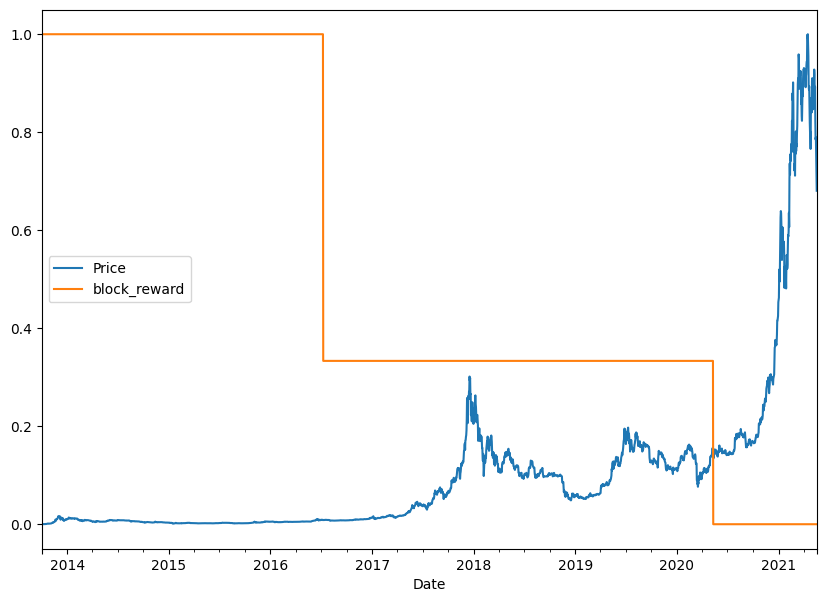

In [106]:
from sklearn.preprocessing import minmax_scale
scaled_price_block_df = pd.DataFrame(minmax_scale(bitcoin_prices_block[["Price","block_reward"]]),
                                   columns = bitcoin_prices_block.columns,
                                   index= bitcoin_prices_block.index)
scaled_price_block_df.plot(figsize=(10,7))

### ***Making a windowed dataset with pandas***

In [107]:
HORIOZN=1
WINDOW_SIZE= 7

In [108]:
bitcoin_prices_windowed = bitcoin_prices_block.copy()

# Add windows columns

for i in range(WINDOW_SIZE):
    bitcoin_prices_windowed[f"Price+{i+1}"] = bitcoin_prices_windowed['Price'].shift(periods=i+1)
bitcoin_prices_windowed.head(20)                           

,Price,block_reward,Price+1,Price+2,Price+3,Price+4,Price+5,Price+6,Price+7
Date,,,,,,,,,
2013-10-01,123.65499,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-10-02,125.45500,25,123.65499,NaN,NaN,NaN,NaN,NaN,NaN
2013-10-03,108.58483,25,125.45500,123.65499,NaN,NaN,NaN,NaN,NaN
2013-10-04,118.67466,25,108.58483,125.45500,123.65499,NaN,NaN,NaN,NaN
2013-10-05,121.33866,25,118.67466,108.58483,125.45500,123.65499,NaN,NaN,NaN
2013-10-06,120.65533,25,121.33866,118.67466,108.58483,125.45500,123.65499,NaN,NaN
2013-10-07,121.79500,25,120.65533,121.33866,118.67466,108.58483,125.45500,123.65499,NaN
2013-10-08,123.03300,25,121.79500,120.65533,121.33866,118.67466,108.58483,125.45500,123.65499
2013-10-09,124.04900,25,123.03300,121.79500,120.65533,121.33866,118.67466,108.58483,125.45500


In [109]:
# create x and y
x = bitcoin_prices_windowed.dropna().drop("Price",axis=1).astype(np.float32)
y = bitcoin_prices_windowed.dropna()["Price"].astype(np.float32)

x.head()

,block_reward,Price+1,Price+2,Price+3,Price+4,Price+5,Price+6,Price+7
Date,,,,,,,,
2013-10-08,25.0,121.794998,120.655327,121.338661,118.674660,108.584831,125.455002,123.654991
2013-10-09,25.0,123.032997,121.794998,120.655327,121.338661,118.674660,108.584831,125.455002
2013-10-10,25.0,124.049004,123.032997,121.794998,120.655327,121.338661,118.674660,108.584831
2013-10-11,25.0,125.961159,124.049004,123.032997,121.794998,120.655327,121.338661,118.674660
2013-10-12,25.0,125.279663,125.961159,124.049004,123.032997,121.794998,120.655327,121.338661


In [110]:
y.head()

Date
2013-10-08    123.032997
2013-10-09    124.049004
2013-10-10    125.961159
2013-10-11    125.279663
2013-10-12    125.927498
Name: Price, dtype: float32

In [111]:
# makeing train and test
split = int(len(x) * 0.8)
x_train , y_train = x[:split],y[:split]
x_test,y_test = x[split:],y[split:]

len(x_train),len(x_test)

(2224, 556)

### ***Model 6: Dense (multivariate time series)***

In [112]:
tf.random.set_seed(42)

model_6 = tf.keras.Sequential([
    layers.Dense(128,activation="relu"),
    layers.Dense(HORIZON)
],name = "model_6_dense_multivariate")

model_6.compile(loss="mae",
               optimizer = tf.keras.optimizers.Adam())

model_6.fit(x_train,y_train,
           epochs=100,
           batch_size=128,
           verbose=0,
           validation_data = (x_test,y_test),
           callbacks = [create_model_checkpoint(model_name="model_6_multivariate.keras")])

In [113]:
# Make sure best model is loaded and evaluate
model_6 = tf.keras.models.load_model("model_experiments/model_6_multivariate.keras")
model_6.evaluate(x_test, y_test)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 282.2900 


565.634033203125

In [114]:
model_6_preds = tf.squeeze(model_6.predict(x_test))
model_6_preds[:10]

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([8842.347 , 8806.318 , 9049.474 , 8731.496 , 8758.092 , 8736.4795,
       8690.363 , 8503.478 , 8474.178 , 8534.683 ], dtype=float32)>

In [115]:
model_6_results = evaluate_preds(y_true=y_test,
                                 y_pred=model_6_preds)
model_6_results

{'mae': 565.63403,
 'mse': 1155174.4,
 'rmse': 1074.7904,
 'mape': 2.5342705,
 'mase': 0.9954527}

In [116]:
model_1_results

{'mae': 562.51544,
 'mse': 1149832.5,
 'rmse': 1072.3024,
 'mape': 2.5091753,
 'mase': 0.9899643}

# ***Model 7: N-BEATS algorithm***

#### ***Building and testing an N-BEATS block layer***

In [117]:
# create NbeatsBlock custom layer
class NBeatsBlock(tf.keras.layers.Layer):
 def __init__(self,
                input_size : int,
                theta_size : int,
                horizon : int,
                n_neurons : int,
                n_layers : int,
                **kwargs):
        super().__init__(**kwargs)
        self.input_size = input_size
        self.theta_size = theta_size
        self.horizon = horizon
        self.n_neurons = n_neurons
        self.n_layers = n_layers
    
        self.hidden = [tf.keras.layers.Dense(n_neurons,activation="relu") for _ in range(n_layers)]
        self.theta_layer = tf.keras.layers.Dense(theta_size,activation="linear",name="theta")
    
 def call(self,inputs):
    x = inputs
    for layer in self.hidden:
        x=layer(x)
    theta = self.theta_layer(x) 
    backcast,forecast = theta[:,:self.input_size],theta[:,-self.horizon:]
    return backcast, forecast
    
    

In [118]:
# setup dummy NBeatBlock layer to represent inputs and outputs
dummy_nbeats_block_layer = NBeatsBlock(input_size=WINDOW_SIZE,
                                      theta_size= WINDOW_SIZE + HORIZON,
                                      horizon = HORIZON,
                                      n_neurons = 128,
                                      n_layers = 4)

In [119]:
dummy_inputs = tf.expand_dims(tf.range(WINDOW_SIZE) + 1 ,axis=0)
dummy_inputs

<tf.Tensor: shape=(1, 7), dtype=int32, numpy=array([[1, 2, 3, 4, 5, 6, 7]], dtype=int32)>

In [120]:
# Pass dummy inputs to dummy NBeatsBlock layer
backcast, forecast = dummy_nbeats_block_layer(dummy_inputs)

print(f"Backcast: {tf.squeeze(backcast.numpy())}")
print(f"Forecast: {tf.squeeze(forecast.numpy())}")

Backcast: [ 0.224511   -0.11874413 -0.51803577  0.0131022   0.20416352 -0.4039942
 -0.07480609]
Forecast: 0.21874773502349854


### ***Preparing data for the N-BEATS algorithm using tf.data***

In [121]:
HORIZON = 1 
WINDOW_SIZE = 7 
     

bitcoin_prices.head()

,Price
Date,
2013-10-01,123.65499
2013-10-02,125.45500
2013-10-03,108.58483
2013-10-04,118.67466
2013-10-05,121.33866


In [122]:
# Add windowed columns
bitcoin_prices_nbeats = bitcoin_prices.copy()
for i in range(WINDOW_SIZE):
    bitcoin_prices_nbeats[f"Price+{i+1}"] = bitcoin_prices_nbeats["Price"].shift(periods=i+1)
bitcoin_prices_nbeats.dropna().head()

,Price,Price+1,Price+2,Price+3,Price+4,Price+5,Price+6,Price+7
Date,,,,,,,,
2013-10-08,123.03300,121.79500,120.65533,121.33866,118.67466,108.58483,125.45500,123.65499
2013-10-09,124.04900,123.03300,121.79500,120.65533,121.33866,118.67466,108.58483,125.45500
2013-10-10,125.96116,124.04900,123.03300,121.79500,120.65533,121.33866,118.67466,108.58483
2013-10-11,125.27966,125.96116,124.04900,123.03300,121.79500,120.65533,121.33866,118.67466
2013-10-12,125.92750,125.27966,125.96116,124.04900,123.03300,121.79500,120.65533,121.33866


In [123]:
# Make features and labels
X = bitcoin_prices_nbeats.dropna().drop("Price", axis=1)
y = bitcoin_prices_nbeats.dropna()["Price"]

# Make train and test sets
split_size = int(len(X) * 0.8)
X_train, y_train = X[:split_size], y[:split_size]
X_test, y_test = X[split_size:], y[split_size:]
len(X_train), len(y_train), len(X_test), len(y_test)

(2224, 2224, 556, 556)

In [152]:
# turn train and test into tensor
train_data = tf.data.Dataset.from_tensor_slices(X_train)
train_label = tf.data.Dataset.from_tensor_slices(y_train)
test_data = tf.data.Dataset.from_tensor_slices(X_test)
test_label= tf.data.Dataset.from_tensor_slices(y_test)

# combine in zip 
train_dataset = tf.data.Dataset.zip((train_data,train_label))
test_dataset = tf.data.Dataset.zip((test_data,test_label))

# create batch
batch_size = 1024
train_dataset = train_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_dataset , test_dataset
                                                        

(<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 7), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.float64, name=None))>,
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 7), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.float64, name=None))>)

In [143]:
N_EPOCHS = 5000 
N_NEURONS = 512 
N_LAYERS = 4
N_STACKS = 30

INPUT_SIZE = WINDOW_SIZE * HORIZON
THETA_SIZE = INPUT_SIZE + HORIZON

INPUT_SIZE, THETA_SIZE

(7, 8)

In [144]:
# double residual stacking
tensor_1 = tf.range(10) + 10
tensor_2 = tf.range(10)

subtracted = layers.subtract([tensor_1,tensor_2])
added = layers.add([tensor_1,tensor_2])

print(f"Input tensors: {tensor_1.numpy()} & {tensor_2.numpy()}")
print(f"Subtracted: {subtracted.numpy()}")
print(f"Added: {added.numpy()}")

Input tensors: [10 11 12 13 14 15 16 17 18 19] & [0 1 2 3 4 5 6 7 8 9]
Subtracted: [10 10 10 10 10 10 10 10 10 10]
Added: [10 12 14 16 18 20 22 24 26 28]


### ***Building, compiling and fitting the N-BEATS algorithm***

In [153]:

 %%time

tf.random.set_seed(42)

# 1. Setup N-BEATS Block layer
nbeats_block_layer = NBeatsBlock(input_size=INPUT_SIZE,
                                 theta_size=THETA_SIZE,
                                 horizon=HORIZON,
                                 n_neurons=N_NEURONS,
                                 n_layers=N_LAYERS,
                                 name="InitialBlock")

# 2. Create input to stacks
stack_input = layers.Input(shape=(INPUT_SIZE,), name="stack_input")

backcast , forecast = nbeats_block_layer(stack_input)

residuals  =layers.subtract([stack_input,backcast],name=f"subtract_00")

for i,_ in enumerate(range(N_STACKS-1)):
    
    backcast,block_forecast = NBeatsBlock(
    input_size=INPUT_SIZE,
    theta_size=THETA_SIZE,
    horizon=HORIZON,
    n_neurons = N_NEURONS,
    n_layers =N_LAYERS,
    name=f"NBeatsBlocks_{i}")(residuals)

#     create double residual stacking'

    residuals = layers.subtract([residuals,backcast],name = f"subtrack_{i}")
    forecast = layers.add([forecast,block_forecast],name=f"add_{i}")
    

model_7 = tf.keras.Model(inputs=stack_input,
                            outputs = forecast,name="model_7_N_BEATS")
    
model_7.compile(loss="mae",
                   optimizer = tf.keras.optimizers.Adam(0.001),
                   metrics = ["mae","mse"])
model_7.fit(train_dataset,
           epochs=N_EPOCHS,
           validation_data = test_dataset,
            verbose=0,
           callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience = 200,restore_best_weights=True),
                       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",patience=100,verbose=1)])

I0000 00:00:1728634412.513187     106 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_40', 440 bytes spill stores, 476 bytes spill loads
ptxas warning : Registers are spilled to local memory in function '__cuda_sm3x_div_rn_noftz_f32_slowpath', 12 bytes spill stores, 12 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_38', 68 bytes spill stores, 92 bytes spill loads
ptxas warning : Registers are spilled to local memory in function '__cuda_sm3x_div_rn_noftz_f32_slowpath', 12 bytes spill stores, 12 bytes spill loads
ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_32', 68 bytes spill stores, 92 bytes spill loads
ptxas warning : Registers are spilled to local memory in function '__cuda_sm3x_div_rn_noftz_f32_slowpath', 12 bytes spill stores, 12 bytes spill loads
ptxas warning : Registers are spilled to local memory in functi


Epoch 234: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.

Epoch 334: ReduceLROnPlateau reducing learning rate to 1.0000000474974514e-05.
CPU times: user 1min 53s, sys: 2.12 s, total: 1min 55s
Wall time: 1min 52s


In [154]:
# Evaluate N-BEATS model on the test dataset
model_7.evaluate(test_dataset)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 576.8463 - mae: 576.8463 - mse: 1185466.0000


[576.8462524414062, 576.8462524414062, 1185466.0]

In [156]:
model_7_preds = make_preds(model_7, test_dataset)
model_7_preds[:10]
     

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([8842.779, 8799.583, 9024.892, 8746.851, 8802.082, 8772.562,
       8636.994, 8520.795, 8520.021, 8508.347], dtype=float32)>

In [157]:
model_7_results = evaluate_preds(y_true=y_test,
                                 y_pred=model_7_preds)
model_7_results

{'mae': 576.84625,
 'mse': 1185465.9,
 'rmse': 1088.791,
 'mape': 2.6435487,
 'mase': 1.015185}

### ***Plotting the N-BEATS architecture***



In [158]:
from tensorflow.keras.utils import plot_model
plot_model(model_7)

### ***Model 8: Creating an ensemble (stacking different models together)***

In [171]:
def get_ensemble_models(horizon=HORIZON,
                       train_data=train_dataset,
                       test_data=test_dataset,
                       num_iter=10,
                       num_epochs=100,
                       loss_fns=["mae","mse","mape"]):
    ensemble_models = []
    for i in range(num_iter):
        for loss_function in loss_fns:
            print(f"optimizing model by reucing:{loss_function } for {num_epochs} epochs,model number:{i}")
            model = tf.keras.Sequential([
                layers.Dense(128,kernel_initializer="he_normal",activation="relu"),
                layers.Dense(128,kernel_initializer="he_normal",activation="relu"),
                layers.Dense(HORIZON)
            ])
            model.compile(loss=loss_function,
                         optimizer = tf.keras.optimizers.Adam(),
                         metrics=["mae","mse"])
            model.fit(train_data,
                     epochs=num_epochs,
                     verbose=0,
                     validation_data=test_data,
                     callbacks = [tf.keras.callbacks.EarlyStopping(monitor="val_loss",
                                                                   patience=200,
                                                                  restore_best_weights=True),
                      tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",
                                                                   patience=100,
                                                                  verbose=1)])
            ensemble_models.append(model)
    return ensemble_models            

In [172]:
%%time

ensemble_models = get_ensemble_models(num_iter=5,
                                     num_epochs=1000)

optimizing model by reucing:mae for 1000 epochs,model number:0

Epoch 548: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.

Epoch 648: ReduceLROnPlateau reducing learning rate to 1.0000000474974514e-05.
optimizing model by reucing:mse for 1000 epochs,model number:0

Epoch 243: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.

Epoch 343: ReduceLROnPlateau reducing learning rate to 1.0000000474974514e-05.
optimizing model by reucing:mape for 1000 epochs,model number:0

Epoch 186: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.

Epoch 286: ReduceLROnPlateau reducing learning rate to 1.0000000474974514e-05.
optimizing model by reucing:mae for 1000 epochs,model number:1

Epoch 886: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
optimizing model by reucing:mse for 1000 epochs,model number:1
optimizing model by reucing:mape for 1000 epochs,model number:1

Epoch 136: ReduceLROnPlateau reducing learning rate to 0.00

### ***Making predictions with an ensemble model***

In [177]:
def make_ensemble_preds(ensemble_models,data):
    ensemble_preds = []
    for model in ensemble_models:
        preds = model.predict(data)
        ensemble_preds.append(preds)
    return tf.constant(tf.squeeze(ensemble_preds))    

In [178]:
ensemble_preds = make_ensemble_preds(ensemble_models=ensemble_models,
                                    data=test_dataset)
ensemble_preds

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


<tf.Tensor: shape=(15, 556), dtype=float32, numpy=
array([[ 8784.459 ,  8803.745 ,  9093.627 , ..., 50090.277 , 47897.75  ,
        46083.266 ],
       [ 8803.513 ,  8799.0625,  8978.387 , ..., 49091.26  , 48144.383 ,
        46735.95  ],
       [ 8813.663 ,  8748.437 ,  9030.139 , ..., 49213.668 , 47434.01  ,
        45525.504 ],
       ...,
       [ 8811.696 ,  8752.945 ,  9047.923 , ..., 50042.297 , 48940.824 ,
        46131.258 ],
       [ 8815.524 ,  8806.148 ,  9039.263 , ..., 50253.035 , 48308.188 ,
        45984.57  ],
       [ 8779.208 ,  8787.096 ,  9080.555 , ..., 50434.477 , 48406.133 ,
        45878.082 ]], dtype=float32)>

In [269]:
ensemble_results = evaluate_preds(y_true=y_test,
                                  y_pred=np.median(ensemble_preds, axis=0)) # take the median across all ensemble predictions
ensemble_results

{'mae': 646.8053,
 'mse': 4876337.5,
 'rmse': 2208.243,
 'mape': 21.584679,
 'mase': 26.554377}

### ***Plotting the prediction intervals (uncertainty estimates) of our ensemble***

In [182]:
def get_upper_lower(preds):
    std = tf.math.reduce_std(preds,axis=0)
    interval = 1.96
    preds_mean = tf.reduce_mean(preds,axis=0)
    lower,upper = preds_mean - interval,preds_mean + interval
    return lower,upper

In [186]:
lower,upper = get_upper_lower(preds=ensemble_preds)
lower ,upper

(<tf.Tensor: shape=(556,), dtype=float32, numpy=
 array([ 8786.163 ,  8774.552 ,  9047.123 ,  8708.559 ,  8748.784 ,
         8722.693 ,  8650.778 ,  8482.464 ,  8449.206 ,  8518.179 ,
         8194.389 ,  8104.7446,  8047.5146,  7613.9326,  7289.722 ,
         7297.476 ,  7045.253 ,  7208.22  ,  7126.6416,  7507.791 ,
         7386.2017,  7720.5864,  7557.342 ,  7388.3267,  7315.2305,
         7303.429 ,  7199.278 ,  7380.924 ,  7500.7246,  7529.27  ,
         7542.743 ,  7333.2686,  7228.154 ,  7176.0415,  7174.1567,
         7221.65  ,  7073.2817,  7095.387 ,  6868.7817,  6580.586 ,
         7381.283 ,  7167.8516,  7145.9663,  7260.57  ,  7283.2305,
         7165.57  ,  7216.4243,  7206.554 ,  7172.5913,  7210.5503,
         7301.238 ,  7381.256 ,  7244.85  ,  7169.187 ,  7160.514 ,
         6943.3193,  7269.2695,  7329.8623,  7344.712 ,  7699.1875,
         8071.9854,  8154.21  ,  7842.2007,  8081.709 ,  8113.7925,
         8161.96  ,  8102.2383,  8730.102 ,  8918.967 ,  8752.415 ,

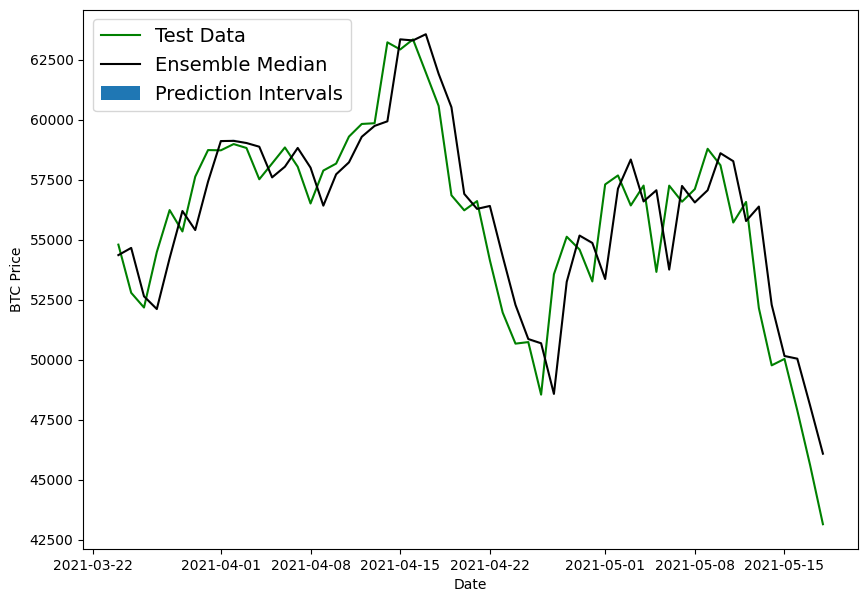

In [187]:

# Get the median values of our ensemble preds
ensemble_median = np.median(ensemble_preds, axis=0)

# Plot the median of our ensemble preds along with the prediction intervals (where the predictions fall between)
offset=500
plt.figure(figsize=(10, 7))
plt.plot(X_test.index[offset:], y_test[offset:], "g", label="Test Data")
plt.plot(X_test.index[offset:], ensemble_median[offset:], "k-", label="Ensemble Median")
plt.xlabel("Date")
plt.ylabel("BTC Price")
plt.fill_between(X_test.index[offset:], 
                 (lower)[offset:], 
                 (upper)[offset:], label="Prediction Intervals")
plt.legend(loc="upper left", fontsize=14);

### ***Model 9: Train a model on the full historical data to make predictions into future***

In [189]:
bitcoin_prices_windowed.head()

,Price,block_reward,Price+1,Price+2,Price+3,Price+4,Price+5,Price+6,Price+7
Date,,,,,,,,,
2013-10-01,123.65499,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2013-10-02,125.45500,25,123.65499,NaN,NaN,NaN,NaN,NaN,NaN
2013-10-03,108.58483,25,125.45500,123.65499,NaN,NaN,NaN,NaN,NaN
2013-10-04,118.67466,25,108.58483,125.45500,123.65499,NaN,NaN,NaN,NaN
2013-10-05,121.33866,25,118.67466,108.58483,125.45500,123.65499,NaN,NaN,NaN


In [194]:
x_all = bitcoin_prices_windowed.drop(["Price","block_reward"],axis=1).dropna().to_numpy()
y_all = bitcoin_prices_windowed.dropna()["Price"].to_numpy()

In [198]:
features_data_all = tf.data.Dataset.from_tensor_slices(x_all)
labels_data_all = tf.data.Dataset.from_tensor_slices(y_all)

dataset_all = tf.data.Dataset.zip((features_data_all,labels_data_all))

batch_size = 1024
dataset_all  = dataset_all.batch(batch_size).prefetch(tf.data.AUTOTUNE)

dataset_all

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 7), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.float64, name=None))>

In [199]:
tf.random.set_seed(42)

# Create model (nice and simple, just to test)
model_9 = tf.keras.Sequential([
  layers.Dense(128, activation="relu"),
  layers.Dense(128, activation="relu"),
  layers.Dense(HORIZON)
])

# Compile
model_9.compile(loss=tf.keras.losses.mae,
                optimizer=tf.keras.optimizers.Adam())

# Fit model on all of the data to make future forecasts
model_9.fit(dataset_all,
            epochs=100,
            )

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 249ms/step - loss: 2607.1790
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1199.0392
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 343.5413
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 612.3108
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 344.7733
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 326.6244
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 393.3317
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 227.2464
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 299.3771
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 276.4973
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 224.9946
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 240.4583
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 202.2930
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 217.5258
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 198.5045


### ***Make predictions on the future***

In [200]:
INTO_FUTURE = 14

In [221]:
def make_future_forecast(values,model,into_future,window_size=WINDOW_SIZE)->list:
    
    
    future_forecast = []
    
    last_window = values[-WINDOW_SIZE:]
    for _ in range(into_future):
        future_pred = model.predict(tf.expand_dims(last_window,axis=0))
        print(f"Predicting on: \n{last_window} -> Prediciton:{tf.squeeze(future_pred).numpy()}\n")
        
        future_forecast.append(tf.squeeze(future_pred).numpy())
        
        last_window = np.append(last_window,future_pred)[-WINDOW_SIZE:]
 
    return future_forecast        
        
    

In [222]:
future_forecast = make_future_forecast(values=y_all,
                                       model=model_9,
                                       into_future=INTO_FUTURE,
                                       window_size=WINDOW_SIZE)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
Predicting on: 
[56573.5554719  52147.82118698 49764.1320816  50032.69313676
 47885.62525472 45604.61575361 43144.47129086] -> Prediciton:55899.8671875

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Predicting on: 
[52147.82118698 49764.1320816  50032.69313676 47885.62525472
 45604.61575361 43144.47129086 55899.8671875 ] -> Prediciton:51275.7109375

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Predicting on: 
[49764.1320816  50032.69313676 47885.62525472 45604.61575361
 43144.47129086 55899.8671875  51275.7109375 ] -> Prediciton:49573.33984375

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Predicting on: 
[50032.69313676 47885.62525472 45604.61575361 43144.47129086
 55899.8671875  51275.7109375  49573.33984375] -> Prediciton:48826.66015625

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Predicting on: 
[47885.62525472 45604.61575361 43144.47129086 55899.8671875
 51275.7109375  49573.33984375 48826.66015625] -> Prediciton:47026.23828125

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Pred

In [230]:
future_forecast[:10]

[55899.867,
 51275.71,
 49573.34,
 48826.66,
 47026.24,
 46818.504,
 48250.69,
 54761.21,
 50412.723,
 49001.97]

### ***Plot future forecasts***

In [231]:

def get_future_dates(start_date, into_future, offset=1):
    start_date = start_date + np.timedelta64(offset, "D") 
    end_date = start_date + np.timedelta64(into_future, "D") 
    return np.arange(start_date, end_date, dtype="datetime64[D]") 
     

In [232]:
# Last timestep of timesteps (currently in np.datetime64 format)
last_timestep = bitcoin_prices.index[-1]
last_timestep

Timestamp('2021-05-18 00:00:00')

In [234]:
next_time_steps = get_future_dates(start_date = last_timestep,
                                  into_future=INTO_FUTURE)
next_time_steps

array(['2021-05-19', '2021-05-20', '2021-05-21', '2021-05-22',
       '2021-05-23', '2021-05-24', '2021-05-25', '2021-05-26',
       '2021-05-27', '2021-05-28', '2021-05-29', '2021-05-30',
       '2021-05-31', '2021-06-01'], dtype='datetime64[D]')

In [235]:
next_time_steps = np.insert(next_time_steps,0,last_timestep)
future_forecast = np.insert(future_forecast ,0, btc_price[-1])
next_time_steps , future_forecast

(array(['2021-05-18', '2021-05-19', '2021-05-20', '2021-05-21',
        '2021-05-22', '2021-05-23', '2021-05-24', '2021-05-25',
        '2021-05-26', '2021-05-27', '2021-05-28', '2021-05-29',
        '2021-05-30', '2021-05-31', '2021-06-01'], dtype='datetime64[D]'),
 array([43144.473, 55899.867, 51275.71 , 49573.34 , 48826.66 , 47026.24 ,
        46818.504, 48250.69 , 54761.21 , 50412.723, 49001.97 , 48204.66 ,
        47578.113, 48909.13 , 50822.832], dtype=float32))

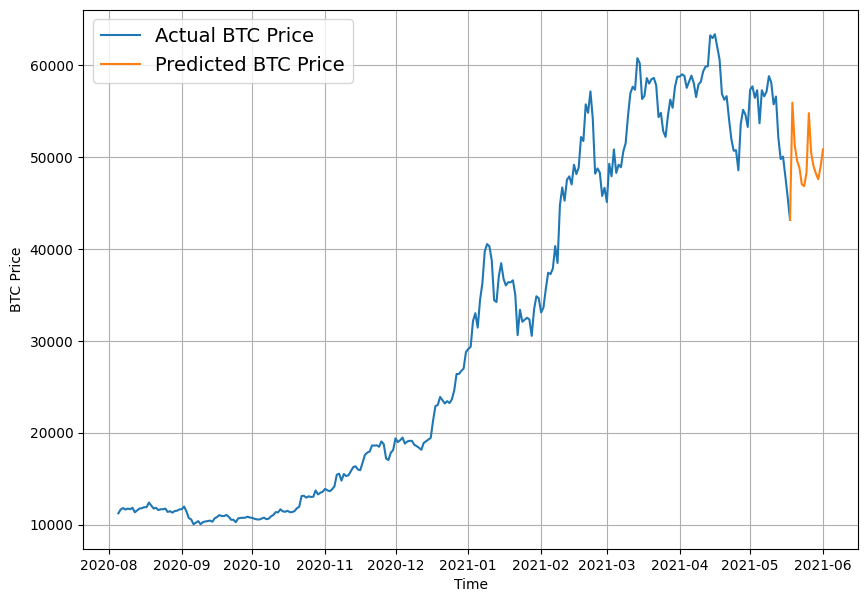

In [236]:
# Plot future price predictions of Bitcoin
plt.figure(figsize=(10, 7))
plot_time_series(bitcoin_prices.index, btc_price, start=2500, format="-", label="Actual BTC Price")
plot_time_series(next_time_steps, future_forecast, format="-", label="Predicted BTC Price")
     

### ***Model 10: Why forecasting is BS (the turkey problem 🦃)***

In [239]:
btc_price_turkey = btc_price.copy()
btc_price_turkey[-1] = btc_price_turkey[-1]/100

In [243]:
btc_price_turkey[-10:]

[58788.2096789273,
 58102.1914262342,
 55715.5466512869,
 56573.5554719043,
 52147.8211869823,
 49764.1320815975,
 50032.6931367648,
 47885.6252547166,
 45604.6157536131,
 431.44471290860304]

In [244]:
# Get the timesteps for the turkey problem 
btc_timesteps_turkey = np.array(bitcoin_prices.index)
btc_timesteps_turkey[-10:]

array(['2021-05-09T00:00:00.000000000', '2021-05-10T00:00:00.000000000',
       '2021-05-11T00:00:00.000000000', '2021-05-12T00:00:00.000000000',
       '2021-05-13T00:00:00.000000000', '2021-05-14T00:00:00.000000000',
       '2021-05-15T00:00:00.000000000', '2021-05-16T00:00:00.000000000',
       '2021-05-17T00:00:00.000000000', '2021-05-18T00:00:00.000000000'],
      dtype='datetime64[ns]')

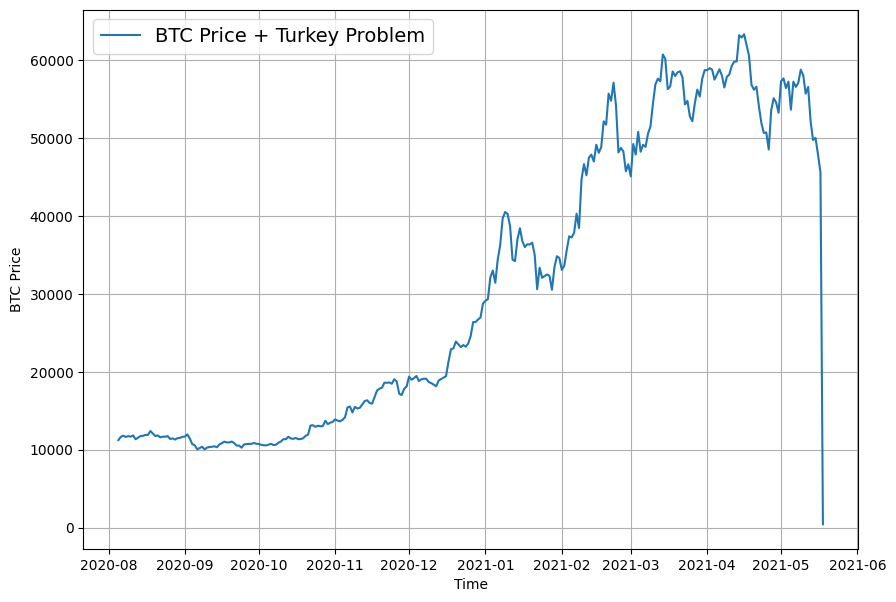

In [246]:
plt.figure(figsize=(10, 7))
plot_time_series(timesteps=btc_timesteps_turkey, 
                 values=btc_price_turkey, 
                 format="-", 
                 label="BTC Price + Turkey Problem", 
                 start=2500)
     

In [247]:
# Create train and test sets for turkey problem data
full_windows, full_labels = make_windows(np.array(btc_price_turkey), window_size=WINDOW_SIZE, horizon=HORIZON)
len(full_windows), len(full_labels)

X_train, X_test, y_train, y_test = make_train_test_splits(full_windows, full_labels)
len(X_train), len(X_test), len(y_train), len(y_test)

(2224, 556, 2224, 556)

### ***Building a turkey model (model to predict on turkey data)***

In [249]:
# Clone model 1 architecture for turkey model and fit the turkey model on the turkey data
turkey_model = tf.keras.models.clone_model(model_1)
turkey_model._name = "Turkey_Model"
turkey_model.compile(loss="mae",
                     optimizer=tf.keras.optimizers.Adam())
turkey_model.fit(X_train, y_train,
                 epochs=100,
                 verbose=1,
                 validation_data=(X_test, y_test),
                 callbacks=[create_model_checkpoint("turkey_model.keras")])
     

Epoch 1/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1256.5776 - val_loss: 1303.3533
Epoch 2/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 204.4332 - val_loss: 1120.4929
Epoch 3/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 180.4518 - val_loss: 1158.3956
Epoch 4/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 168.3947 - val_loss: 1092.8655
Epoch 5/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 146.2367 - val_loss: 1010.5692
Epoch 6/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 141.4925 - val_loss: 813.6303
Epoch 7/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 133.4930 - val_loss: 766.7127
Epoch 8/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 131.1106 - val_loss: 745.2400
Epoch 9/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 131.2079 - val_loss: 779.2918
Epoch 10/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 122.9076 - val_loss: 745.2054
Epoch 11/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 132.0929 - val_loss: 738.2119
Epoch 12/100


In [257]:
# Evaluate turkey model on test data
turkey_model.evaluate(X_test, y_test)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 289.6917 


642.7345581054688

In [258]:
# Load best model and evaluate on test data
turkey_model = tf.keras.models.load_model("model_experiments/turkey_model.keras")
turkey_model.evaluate(X_test, y_test)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 289.6917 


642.7345581054688

In [259]:
# Make predictions with Turkey model
turkey_preds = make_preds(turkey_model, X_test)
turkey_preds[:10]

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([8788.212, 8741.872, 9030.844, 8732.688, 8720.049, 8713.949,
       8653.816, 8484.046, 8431.519, 8511.679], dtype=float32)>

In [260]:
turkey_results = evaluate_preds(y_true=y_test,
                                y_pred=turkey_preds)
turkey_results

{'mae': 642.73456,
 'mse': 4902171.0,
 'rmse': 2214.0847,
 'mape': 21.620731,
 'mase': 26.550861}

In [261]:
model_1_results

{'mae': 562.51544,
 'mse': 1149832.5,
 'rmse': 1072.3024,
 'mape': 2.5091753,
 'mase': 0.9899643}

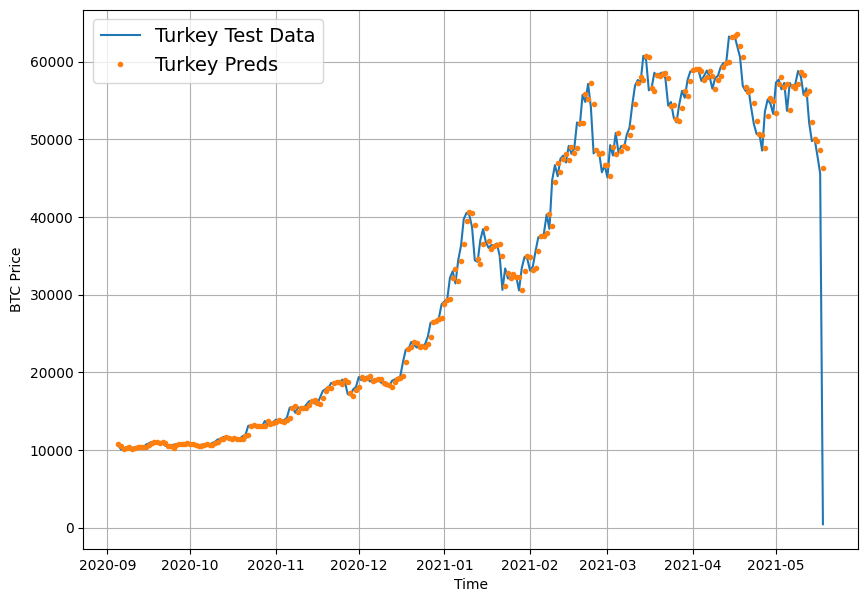

In [262]:
plt.figure(figsize=(10, 7))
# plot_time_series(timesteps=btc_timesteps_turkey[:split_size], values=btc_price_turkey[:split_size], label="Train Data")
offset=300
plot_time_series(timesteps=btc_timesteps_turkey[-len(X_test):], 
                 values=btc_price_turkey[-len(y_test):], 
                 format="-", 
                 label="Turkey Test Data", start=offset)
plot_time_series(timesteps=btc_timesteps_turkey[-len(X_test):],
                 values=turkey_preds, 
                 label="Turkey Preds", 
                 start=offset);

### ***Compare Models***

In [271]:
# Compare different model results (w = window, h = horizon, e.g. w=7 means a window size of 7)
model_results = pd.DataFrame({"naive_model": naive_result,
                              "model_1_dense_w7_h1": model_1_results,
                              "model_2_dense_w30_h1": model_2_results,
                              "model_3_dense_w30_h7": model_3_results,
                              "model_4_CONV1D": model_4_results,
                              "model_5_LSTM": model_5_results,
                              "model_6_multivariate": model_6_results,
                              "model_8_NBEATs": model_7_results,
                              "model_9_ensemble": ensemble_results,
                              "model_10_turkey": turkey_results}).T
model_results.head(10)

,mae,mse,rmse,mape,mase
naive_model,567.980225,1147547.000,1071.236206,2.516525,1.001368
model_1_dense_w7_h1,562.515442,1149832.500,1072.302368,2.509175,0.989964
model_2_dense_w30_h1,619.830444,1302923.375,1141.456665,2.799040,1.085436
model_3_dense_w30_h7,1265.513428,5568592.500,2359.786621,5.676088,2.256005
model_4_CONV1D,571.246643,1180574.125,1086.542236,2.561587,1.005330
model_5_LSTM,583.670410,1210980.625,1100.445679,2.623549,1.027195
model_6_multivariate,565.634033,1155174.375,1074.790405,2.534271,0.995453
model_8_NBEATs,576.846252,1185465.875,1088.791016,2.643549,1.015185
model_9_ensemble,646.805298,4876337.500,2208.242920,21.584679,26.554377
model_10_turkey,642.734558,4902171.000,2214.084717,21.620731,26.550861


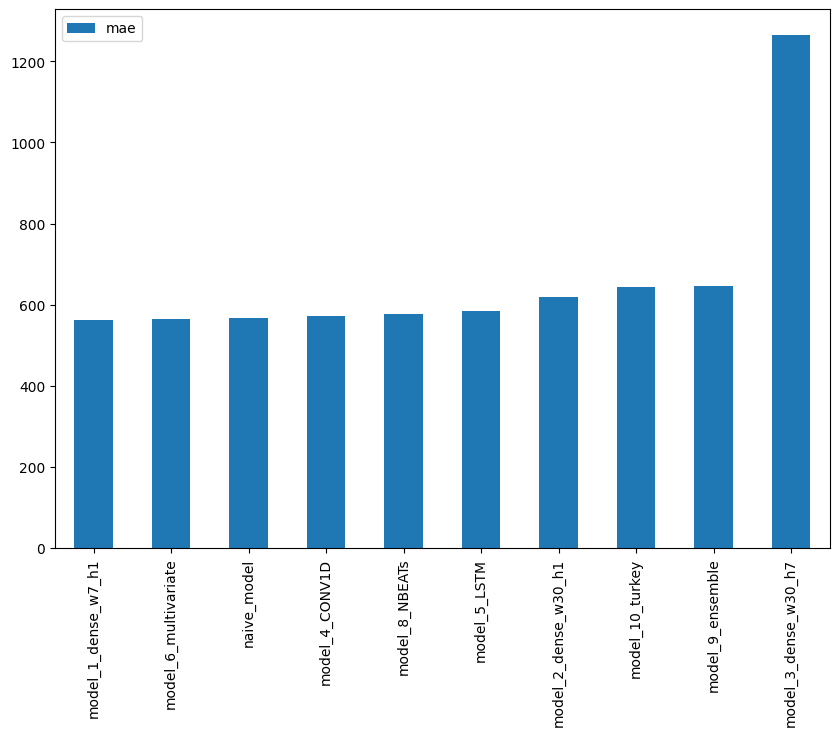

In [272]:
# Sort model results by MAE and plot them
model_results[["mae"]].sort_values(by="mae").plot(figsize=(10, 7), kind="bar");